In [ ]:

!pip install pandas requests folium

import os
import json
import time
import hashlib
import requests
import pandas as pd
import folium

from datetime import datetime, timezone
from pathlib import Path
from google.colab import drive

print("Library berhasil disiapkan!")


Library berhasil disiapkan!


In [ ]:

drive.mount('/content/drive')

NIM = "2501010381"

BASE_DIR = Path(
    f"/content/drive/MyDrive/akomodasi_kintamani_{NIM}"
)

# Membuat struktur folder proyek
folders = [
    "data/raw",
    "data/interim",
    "notebooks",
    "docs",
    "reports"
]

for folder in folders:
    (BASE_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("Folder proyek berhasil dibuat!")
print(BASE_DIR)


Mounted at /content/drive
Folder proyek berhasil dibuat!
/content/drive/MyDrive/akomodasi_kintamani_2501010381


In [ ]:

URL = "https://overpass-api.de/api/interpreter"

HEADERS = {
    "User-Agent":
    "INSTIKI-BIFP243-Praktikum/1.0 (NIM: 2501010381)"
}

QUERY = """
[out:json][timeout:90];

area["name"="Kintamani"]
     ["boundary"="administrative"]
     ["admin_level"="6"]->.kec;

nwr["tourism"~"^(hotel|guest_house|hostel|motel|apartment|chalet)$"]
   (area.kec);

out center tags;
"""

# Menyimpan query final
query_path = BASE_DIR / "docs/query_overpass.txt"
query_path.write_text(QUERY, encoding="utf-8")

print("Query Overpass berhasil disiapkan!")
print(QUERY)


Query Overpass berhasil disiapkan!

[out:json][timeout:90];

area["name"="Kintamani"]
     ["boundary"="administrative"]
     ["admin_level"="6"]->.kec;

nwr["tourism"~"^(hotel|guest_house|hostel|motel|apartment|chalet)$"]
   (area.kec);

out center tags;



In [ ]:

def ambil_overpass(query, maks_percobaan=4, jeda=10):

    for percobaan in range(1, maks_percobaan + 1):

        print(f"\nPercobaan ke-{percobaan}...")

        try:
            response = requests.post(
                URL,
                data={"data": query},
                headers=HEADERS,
                timeout=180
            )

            print("HTTP Status:", response.status_code)

            if response.status_code == 200:
                print("Berhasil mengambil data!")
                return response

            print("Pesan server:")
            print(response.text[:1000])

            # Jangan mengulang jika query ditolak
            if response.status_code not in [429, 502, 503, 504]:
                response.raise_for_status()

        except requests.Timeout:
            print("Koneksi timeout!")

        except requests.ConnectionError as e:
            print("Masalah koneksi:", e)

        except requests.HTTPError as e:
            print("HTTP Error:", e)
            raise

        if percobaan < maks_percobaan:
            print(f"Menunggu {jeda} detik...")
            time.sleep(jeda)
            jeda *= 2

    raise RuntimeError(
        "Overpass API gagal setelah beberapa percobaan. "
        "Periksa pesan server di atas."
    )


print("Fungsi debugging berhasil diperbarui!")


Fungsi debugging berhasil diperbarui!


In [ ]:

# Mengambil data dari Overpass
response = ambil_overpass(QUERY)

# Membaca respons JSON
data = response.json()

# Membuat timestamp
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Menyimpan respons mentah tanpa mengubah isi respons
raw_path = BASE_DIR / "data/raw" / (
    f"osm_akomodasi_kintamani_{stamp}.json"
)

raw_path.write_text(
    response.text,
    encoding="utf-8"
)

# Menghitung MD5 untuk provenance
md5_hash = hashlib.md5(
    raw_path.read_bytes()
).hexdigest()

print("AKUISISI BERHASIL!")
print("Jumlah elemen:", len(data["elements"]))
print("File JSON:", raw_path.name)
print("MD5:", md5_hash)



Percobaan ke-1...
HTTP Status: 200
Berhasil mengambil data!
AKUISISI BERHASIL!
Jumlah elemen: 32
File JSON: osm_akomodasi_kintamani_20261109_041952.json
MD5: d21fb614f935226c50ed00a5417b0b3f


In [ ]:

def ratakan(elements):

    baris = []

    for e in elements:

        tg = e.get("tags", {})

        # Node menggunakan koordinat langsung
        # Way dan relation menggunakan center
        pusat = e.get("center", e)

        baris.append({
            "osm_type": e["type"],
            "osm_id": e["id"],
            "nama": tg.get("name"),
            "jenis": tg.get("tourism"),
            "lat": pusat.get("lat"),
            "lon": pusat.get("lon"),
            "desa": tg.get("addr:village"),
            "bintang": tg.get("stars"),
            "jumlah_kamar": tg.get("rooms"),
            "website": (
                tg.get("website")
                or tg.get("contact:website")
            ),
            "url_osm": (
                f"https://www.openstreetmap.org/"
                f"{e['type']}/{e['id']}"
            )
        })

    return pd.DataFrame(baris)


akomodasi = ratakan(data["elements"])

print("Proses flattening berhasil!")
print("Jumlah baris:", len(akomodasi))

akomodasi.head(10)


Proses flattening berhasil!
Jumlah baris: 32


,osm_type,osm_id,nama,jenis,lat,lon,desa,bintang,jumlah_kamar,website,url_osm
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,None,None,None,http://lakeviewbali.com/en/,https://www.openstreetmap.org/node/1977779907
1,node,2107226701,Arlina,guest_house,-8.249815,115.398465,None,None,None,None,https://www.openstreetmap.org/node/2107226701
2,node,2107227001,Toya Devasya Resort,hotel,-8.250164,115.399798,None,None,None,None,https://www.openstreetmap.org/node/2107227001
3,node,4150326329,Guesthouse,hotel,-8.281456,115.362223,None,None,None,None,https://www.openstreetmap.org/node/4150326329
4,node,4297310696,The Cave Hotel,hotel,-8.280748,115.362048,None,2,5,None,https://www.openstreetmap.org/node/4297310696
5,node,4401927990,batur montáin view,hotel,-8.260754,115.338771,None,None,None,None,https://www.openstreetmap.org/node/4401927990
6,node,4863479822,Miranda Homestay & Restaurant,guest_house,-8.246313,115.327402,None,None,None,None,https://www.openstreetmap.org/node/4863479822
7,node,4905949623,Lava Stone Hostel,hostel,-8.250325,115.397136,None,None,None,None,https://www.openstreetmap.org/node/4905949623
8,node,5065920543,The Volcania Guesthouse,hotel,-8.283796,115.365242,None,None,None,None,https://www.openstreetmap.org/node/5065920543
9,node,5175562421,Entrance to: Bunbulan Hill Hostel,hostel,-8.222014,115.395349,None,None,None,None,https://www.openstreetmap.org/node/5175562421


In [ ]:

csv_path = (
    BASE_DIR /
    "data/interim/akomodasi_kintamani.csv"
)

akomodasi.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)

print("Dataset CSV berhasil disimpan!")
print(csv_path)


Dataset CSV berhasil disimpan!
/content/drive/MyDrive/akomodasi_kintamani_2501010381/data/interim/akomodasi_kintamani.csv


In [ ]:

print("===== PEMERIKSAAN DATA =====")

# 1. Pemeriksaan duplikat
duplikat = akomodasi.duplicated(
    subset=["osm_type", "osm_id"]
).sum()

print("Data duplikat:", duplikat)

# 2. Nama kosong
tanpa_nama = akomodasi["nama"].isna().sum()

print("Data tanpa nama:", tanpa_nama)

# 3. Koordinat kosong
koordinat_kosong = akomodasi[
    ["lat", "lon"]
].isna().any(axis=1).sum()

print("Koordinat kosong:", koordinat_kosong)

# 4. Kolom dengan banyak nilai kosong
persentase_kosong = (
    akomodasi.isna().mean() * 100
).round(2)

print("\nPersentase nilai kosong:")
print(persentase_kosong)

# 5. Jumlah akomodasi berdasarkan jenis
print("\nJumlah berdasarkan jenis:")
print(akomodasi["jenis"].value_counts(dropna=False))

# 6. Jumlah akomodasi tanpa nama
print("\nJumlah tanpa nama:", tanpa_nama)


===== PEMERIKSAAN DATA =====
Data duplikat: 0
Data tanpa nama: 1
Koordinat kosong: 0

Persentase nilai kosong:
osm_type          0.00
osm_id            0.00
nama              3.12
jenis             0.00
lat               0.00
lon               0.00
desa            100.00
bintang          96.88
jumlah_kamar     93.75
website          93.75
url_osm           0.00
dtype: float64

Jumlah berdasarkan jenis:
jenis
hotel          16
guest_house     9
hostel          4
chalet          2
motel           1
Name: count, dtype: int64

Jumlah tanpa nama: 1


In [ ]:

# Memastikan koordinat berupa angka
peta_data = akomodasi.dropna(
    subset=["lat", "lon"]
).copy()

peta_data["lat"] = pd.to_numeric(
    peta_data["lat"], errors="coerce"
)

peta_data["lon"] = pd.to_numeric(
    peta_data["lon"], errors="coerce"
)

peta_data = peta_data.dropna(
    subset=["lat", "lon"]
)

if len(peta_data) == 0:
    raise ValueError("Tidak ada koordinat valid!")

# Menentukan pusat peta
pusat_lat = peta_data["lat"].mean()
pusat_lon = peta_data["lon"].mean()

# Membuat peta tanpa tile bawaan
peta = folium.Map(
    location=[pusat_lat, pusat_lon],
    zoom_start=11,
    tiles=None
)

# Menambahkan basemap Esri
folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/"
        "ArcGIS/rest/services/World_Street_Map/"
        "MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles © Esri",
    name="Esri World Street Map",
    overlay=False,
    control=True
).add_to(peta)

# Menambahkan marker akomodasi
for _, row in peta_data.iterrows():

    nama = (
        row["nama"]
        if pd.notna(row["nama"])
        else "Tanpa nama"
    )

    jenis = row["jenis"]

    folium.Marker(
        location=[row["lat"], row["lon"]],
        popup=f"{nama} - {jenis}",
        tooltip=nama
    ).add_to(peta)

# Menyimpan peta
map_path = (
    BASE_DIR /
    "reports/peta_akomodasi_kintamani.html"
)

peta.save(str(map_path))

print("Peta berhasil dibuat!")
print("Jumlah marker:", len(peta_data))
print("Lokasi file:", map_path)

peta


Peta berhasil dibuat!
Jumlah marker: 32
Lokasi file: /content/drive/MyDrive/akomodasi_kintamani_2501010381/reports/peta_akomodasi_kintamani.html


In [ ]:

# Data pembanding dari BPS
data_bps = pd.DataFrame([
    {
        "sumber": "BPS",
        "tahun_data": 2024,
        "kategori": "Hotel",
        "jumlah": 4,
        "satuan": "Desa/kelurahan"
    },
    {
        "sumber": "BPS",
        "tahun_data": 2024,
        "kategori": "Penginapan",
        "jumlah": 10,
        "satuan": "Desa/kelurahan"
    },
    {
        "sumber": "OSM",
        "tahun_data": 2026,
        "kategori": "Hotel",
        "jumlah": 16,
        "satuan": "Objek akomodasi"
    },
    {
        "sumber": "OSM",
        "tahun_data": 2026,
        "kategori": "Guest House",
        "jumlah": 9,
        "satuan": "Objek akomodasi"
    },
    {
        "sumber": "OSM",
        "tahun_data": 2026,
        "kategori": "Hostel",
        "jumlah": 4,
        "satuan": "Objek akomodasi"
    },
    {
        "sumber": "OSM",
        "tahun_data": 2026,
        "kategori": "Chalet",
        "jumlah": 2,
        "satuan": "Objek akomodasi"
    },
    {
        "sumber": "OSM",
        "tahun_data": 2026,
        "kategori": "Motel",
        "jumlah": 1,
        "satuan": "Objek akomodasi"
    }
])

# Menyimpan hasil perbandingan
bps_path = BASE_DIR / "docs/perbandingan_bps.csv"

data_bps.to_csv(
    bps_path,
    index=False,
    encoding="utf-8-sig"
)

print("Perbandingan BPS berhasil disimpan!")
display(data_bps)


Perbandingan BPS berhasil disimpan!


,sumber,tahun_data,kategori,jumlah,satuan
0,BPS,2024,Hotel,4,Desa/kelurahan
1,BPS,2024,Penginapan,10,Desa/kelurahan
2,OSM,2026,Hotel,16,Objek akomodasi
3,OSM,2026,Guest House,9,Objek akomodasi
4,OSM,2026,Hostel,4,Objek akomodasi
5,OSM,2026,Chalet,2,Objek akomodasi
6,OSM,2026,Motel,1,Objek akomodasi


In [ ]:

# Membuat dokumentasi provenance

provenance = {
    "project": "Akuisisi Data Akomodasi Kecamatan Kintamani",
    "nim": "2501010381",
    "platform": "Google Colab",
    "programming_language": "Python",
    "library": [
        "Pandas",
        "Requests",
        "Folium"
    ],
    "data_source": {
        "name": "OpenStreetMap",
        "api": "Overpass API",
        "endpoint": URL,
        "access_date": "2026-11-09",
        "http_status": response.status_code
    },
    "geographic_scope": "Kecamatan Kintamani, Kabupaten Bangli",
    "categories": [
        "hotel",
        "guest_house",
        "hostel",
        "motel",
        "apartment",
        "chalet"
    ],
    "acquisition": {
        "method": "Overpass API",
        "query_file": "docs/query_overpass.txt",
        "total_elements": len(data["elements"]),
        "raw_file": raw_path.name,
        "hash_algorithm": "MD5",
        "md5": md5_hash
    },
    "comparison_source": {
        "name": "BPS Kabupaten Bangli",
        "publication": "Kecamatan Kintamani Dalam Angka 2025",
        "reference_year": 2024
    },
    "limitations": [
        "Data OSM merupakan objek individual.",
        "Data BPS menggunakan satuan desa/kelurahan.",
        "Satu objek OSM belum tentu mewakili satu usaha unik.",
        "Atribut akomodasi dapat tidak lengkap.",
        "Batas administratif perlu diverifikasi."
    ]
}

provenance_path = BASE_DIR / "docs/provenance.json"

with open(provenance_path, "w", encoding="utf-8") as f:
    json.dump(
        provenance,
        f,
        indent=4,
        ensure_ascii=False
    )

print("Provenance berhasil dibuat!")
print(provenance_path)


Provenance berhasil dibuat!
/content/drive/MyDrive/akomodasi_kintamani_2501010381/docs/provenance.json


In [ ]:

data_dictionary = pd.DataFrame([
    {
        "nama_kolom": "osm_type",
        "tipe_data": "String",
        "deskripsi": "Jenis elemen OpenStreetMap: node, way, atau relation"
    },
    {
        "nama_kolom": "osm_id",
        "tipe_data": "Integer",
        "deskripsi": "Identitas unik elemen OpenStreetMap"
    },
    {
        "nama_kolom": "nama",
        "tipe_data": "String",
        "deskripsi": "Nama objek akomodasi"
    },
    {
        "nama_kolom": "jenis",
        "tipe_data": "String",
        "deskripsi": "Kategori akomodasi berdasarkan tag tourism"
    },
    {
        "nama_kolom": "lat",
        "tipe_data": "Float",
        "deskripsi": "Koordinat lintang objek"
    },
    {
        "nama_kolom": "lon",
        "tipe_data": "Float",
        "deskripsi": "Koordinat bujur objek"
    },
    {
        "nama_kolom": "desa",
        "tipe_data": "String",
        "deskripsi": "Informasi desa dari tag addr:village"
    },
    {
        "nama_kolom": "bintang",
        "tipe_data": "String",
        "deskripsi": "Informasi klasifikasi bintang akomodasi jika tersedia"
    },
    {
        "nama_kolom": "jumlah_kamar",
        "tipe_data": "String",
        "deskripsi": "Jumlah kamar jika dicantumkan di OpenStreetMap"
    },
    {
        "nama_kolom": "website",
        "tipe_data": "String",
        "deskripsi": "Alamat website resmi jika tersedia"
    },
    {
        "nama_kolom": "url_osm",
        "tipe_data": "String",
        "deskripsi": "Tautan menuju elemen OpenStreetMap"
    }
])

dictionary_path = (
    BASE_DIR / "docs/data_dictionary.csv"
)

data_dictionary.to_csv(
    dictionary_path,
    index=False,
    encoding="utf-8-sig"
)

print("Data dictionary berhasil dibuat!")
display(data_dictionary)


Data dictionary berhasil dibuat!


,nama_kolom,tipe_data,deskripsi
0,osm_type,String,"Jenis elemen OpenStreetMap: node, way, atau re..."
1,osm_id,Integer,Identitas unik elemen OpenStreetMap
2,nama,String,Nama objek akomodasi
3,jenis,String,Kategori akomodasi berdasarkan tag tourism
4,lat,Float,Koordinat lintang objek
5,lon,Float,Koordinat bujur objek
6,desa,String,Informasi desa dari tag addr:village
7,bintang,String,Informasi klasifikasi bintang akomodasi jika t...
8,jumlah_kamar,String,Jumlah kamar jika dicantumkan di OpenStreetMap
9,website,String,Alamat website resmi jika tersedia


In [ ]:

ethics = pd.DataFrame([
    {
        "aspek": "Sumber data",
        "pemeriksaan": "Menggunakan sumber data publik OpenStreetMap",
        "status": "Dilakukan"
    },
    {
        "aspek": "Privasi",
        "pemeriksaan": "Tidak mengumpulkan data pribadi pengunjung atau pelanggan",
        "status": "Dilakukan"
    },
    {
        "aspek": "Lisensi",
        "pemeriksaan": "Mencantumkan atribusi OpenStreetMap dan memperhatikan ODbL",
        "status": "Perlu diterapkan pada publikasi"
    },
    {
        "aspek": "Transparansi",
        "pemeriksaan": "Mencatat API, query, tanggal pengambilan, dan sumber data",
        "status": "Dilakukan"
    },
    {
        "aspek": "Kualitas data",
        "pemeriksaan": "Memeriksa duplikat, nama kosong, dan koordinat",
        "status": "Dilakukan"
    },
    {
        "aspek": "Akurasi lokasi",
        "pemeriksaan": "Memverifikasi seluruh titik terhadap batas kecamatan",
        "status": "Belum dilakukan"
    },
    {
        "aspek": "Kelengkapan",
        "pemeriksaan": "Mencatat atribut yang tidak tersedia atau kosong",
        "status": "Dilakukan"
    },
    {
        "aspek": "Penggunaan data",
        "pemeriksaan": "Tidak mengklaim data OSM sebagai data resmi BPS",
        "status": "Dilakukan"
    },
    {
        "aspek": "Perbandingan",
        "pemeriksaan": "Memperhatikan perbedaan satuan pengukuran OSM dan BPS",
        "status": "Dilakukan"
    }
])

ethics_path = (
    BASE_DIR / "docs/data_ethics_checklist.csv"
)

ethics.to_csv(
    ethics_path,
    index=False,
    encoding="utf-8-sig"
)

print("Data Ethics Checklist berhasil dibuat!")
display(ethics)


Data Ethics Checklist berhasil dibuat!


,aspek,pemeriksaan,status
0,Sumber data,Menggunakan sumber data publik OpenStreetMap,Dilakukan
1,Privasi,Tidak mengumpulkan data pribadi pengunjung ata...,Dilakukan
2,Lisensi,Mencantumkan atribusi OpenStreetMap dan memper...,Perlu diterapkan pada publikasi
3,Transparansi,"Mencatat API, query, tanggal pengambilan, dan ...",Dilakukan
4,Kualitas data,"Memeriksa duplikat, nama kosong, dan koordinat",Dilakukan
5,Akurasi lokasi,Memverifikasi seluruh titik terhadap batas kec...,Belum dilakukan
6,Kelengkapan,Mencatat atribut yang tidak tersedia atau kosong,Dilakukan
7,Penggunaan data,Tidak mengklaim data OSM sebagai data resmi BPS,Dilakukan
8,Perbandingan,Memperhatikan perbedaan satuan pengukuran OSM ...,Dilakukan


In [ ]:

# Mengambil 10 sampel secara acak
sampel = akomodasi.sample(
    n=min(10, len(akomodasi)),
    random_state=42
).copy()

# Menambahkan kolom validasi manual
sampel["nama_valid"] = ""
sampel["jenis_valid"] = ""
sampel["lokasi_valid"] = ""
sampel["masuk_kintamani"] = ""
sampel["catatan"] = ""

# Menyimpan hasil sampel
sample_path = (
    BASE_DIR / "docs/validasi_10_sampel.csv"
)

sampel.to_csv(
    sample_path,
    index=False,
    encoding="utf-8-sig"
)

print("10 sampel berhasil dipilih!")
print("File:", sample_path)

display(
    sampel[
        [
            "nama",
            "jenis",
            "lat",
            "lon",
            "url_osm"
        ]
    ]
)


10 sampel berhasil dipilih!
File: /content/drive/MyDrive/akomodasi_kintamani_2501010381/docs/validasi_10_sampel.csv


,nama,jenis,lat,lon,url_osm
29,Batur Sunrise Guesthouse,hotel,-8.249020,115.400863,https://www.openstreetmap.org/node/13068182153
15,Caldera,hotel,-8.279139,115.367364,https://www.openstreetmap.org/node/6451134585
24,Bunbulan Panorama Villas,guest_house,-8.222736,115.397971,https://www.openstreetmap.org/node/9769685089
17,Segara Hotel,hotel,-8.278086,115.379134,https://www.openstreetmap.org/node/7058054537
8,The Volcania Guesthouse,hotel,-8.283796,115.365242,https://www.openstreetmap.org/node/5065920543
9,Entrance to: Bunbulan Hill Hostel,hostel,-8.222014,115.395349,https://www.openstreetmap.org/node/5175562421
30,Lava Bali and Hot Spring,hotel,-8.250311,115.396374,https://www.openstreetmap.org/node/13284479326
25,Villa Jempana,hotel,-8.231158,115.410556,https://www.openstreetmap.org/node/9778735917
12,Hut,chalet,-8.242693,115.387587,https://www.openstreetmap.org/node/5479746121
0,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,https://www.openstreetmap.org/node/1977779907


In [ ]:

# Membuat lembar validasi manual

validasi = sampel[
    [
        "osm_type",
        "osm_id",
        "nama",
        "jenis",
        "lat",
        "lon",
        "url_osm"
    ]
].copy()

# Kolom pemeriksaan
kolom_validasi = [
    "nama_valid",
    "jenis_valid",
    "koordinat_valid",
    "masuk_kintamani",
    "catatan",
    "tanggal_pemeriksaan"
]

for kolom in kolom_validasi:
    validasi[kolom] = "Belum diperiksa"

# Menyimpan file terpisah
validasi_path = (
    BASE_DIR / "docs/validasi_10_sampel.csv"
)

validasi.to_csv(
    validasi_path,
    index=False,
    encoding="utf-8-sig"
)

print("Lembar validasi berhasil diperbarui!")
display(validasi)


Lembar validasi berhasil diperbarui!


,osm_type,osm_id,nama,jenis,lat,lon,url_osm,nama_valid,jenis_valid,koordinat_valid,masuk_kintamani,catatan,tanggal_pemeriksaan
29,node,13068182153,Batur Sunrise Guesthouse,hotel,-8.249020,115.400863,https://www.openstreetmap.org/node/13068182153,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa
15,node,6451134585,Caldera,hotel,-8.279139,115.367364,https://www.openstreetmap.org/node/6451134585,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa
24,node,9769685089,Bunbulan Panorama Villas,guest_house,-8.222736,115.397971,https://www.openstreetmap.org/node/9769685089,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa
17,node,7058054537,Segara Hotel,hotel,-8.278086,115.379134,https://www.openstreetmap.org/node/7058054537,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa
8,node,5065920543,The Volcania Guesthouse,hotel,-8.283796,115.365242,https://www.openstreetmap.org/node/5065920543,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa
9,node,5175562421,Entrance to: Bunbulan Hill Hostel,hostel,-8.222014,115.395349,https://www.openstreetmap.org/node/5175562421,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa
30,node,13284479326,Lava Bali and Hot Spring,hotel,-8.250311,115.396374,https://www.openstreetmap.org/node/13284479326,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa
25,node,9778735917,Villa Jempana,hotel,-8.231158,115.410556,https://www.openstreetmap.org/node/9778735917,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa
12,node,5479746121,Hut,chalet,-8.242693,115.387587,https://www.openstreetmap.org/node/5479746121,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa
0,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,https://www.openstreetmap.org/node/1977779907,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa,Belum diperiksa


In [ ]:

# Membaca hasil validasi
hasil_validasi = pd.read_csv(validasi_path)

# Menghitung status pemeriksaan
print("===== HASIL VALIDASI =====")

for kolom in [
    "nama_valid",
    "jenis_valid",
    "koordinat_valid",
    "masuk_kintamani"
]:
    print(
        f"{kolom}:",
        hasil_validasi[kolom].value_counts(
            dropna=False
        ).to_dict()
    )

print(
    "\nTotal sampel:",
    len(hasil_validasi)
)

print(
    "Belum diperiksa:",
    (hasil_validasi["nama_valid"] ==
     "Belum diperiksa").sum()
)


===== HASIL VALIDASI =====
nama_valid: {'Belum diperiksa': 10}
jenis_valid: {'Belum diperiksa': 10}
koordinat_valid: {'Belum diperiksa': 10}
masuk_kintamani: {'Belum diperiksa': 10}

Total sampel: 10
Belum diperiksa: 10


In [ ]:

import pandas as pd

# Lokasi file validasi
validasi_path = BASE_DIR / "docs" / "validasi_10_sampel.csv"

# Membaca CSV yang sudah ada
validasi = pd.read_csv(validasi_path)

# Hasil pemeriksaan 10 sampel
hasil_validasi = {
    13068182153: {
        "nama_valid": "Sesuai",
        "jenis_valid": "Sesuai",
        "koordinat_valid": "Sesuai",
        "catatan": "Nama, jenis, dan koordinat sesuai dengan OSM. tourism=hotel."
    },
    6451134585: {
        "nama_valid": "Sesuai",
        "jenis_valid": "Sesuai",
        "koordinat_valid": "Sesuai",
        "catatan": "Nama, jenis, dan koordinat sesuai dengan OSM. tourism=hotel."
    },
    9769685089: {
        "nama_valid": "Sesuai",
        "jenis_valid": "Sesuai",
        "koordinat_valid": "Sesuai",
        "catatan": "Nama, jenis, dan koordinat sesuai dengan OSM. tourism=guest_house."
    },
    7058054537: {
        "nama_valid": "Sesuai",
        "jenis_valid": "Sesuai",
        "koordinat_valid": "Sesuai",
        "catatan": "Nama, jenis, dan koordinat sesuai dengan OSM. tourism=hotel."
    },
    5065920543: {
        "nama_valid": "Sesuai",
        "jenis_valid": "Sesuai",
        "koordinat_valid": "Sesuai",
        "catatan": "Nama, jenis, dan koordinat sesuai dengan OSM. tourism=hotel."
    },
    5175562421: {
        "nama_valid": "Sesuai",
        "jenis_valid": "Sesuai",
        "koordinat_valid": "Sesuai",
        "catatan": "Tag sesuai dengan OSM, tetapi nama Entrance to mengindikasikan kemungkinan titik akses masuk hostel."
    },
    13284479326: {
        "nama_valid": "Sesuai",
        "jenis_valid": "Sesuai",
        "koordinat_valid": "Sesuai",
        "catatan": "Nama, jenis, dan koordinat sesuai dengan OSM. tourism=hotel; fungsi Hot Spring perlu dikonfirmasi."
    },
    9778735917: {
        "nama_valid": "Sesuai",
        "jenis_valid": "Sesuai",
        "koordinat_valid": "Sesuai",
        "catatan": "Nama, jenis, dan koordinat sesuai dengan OSM. tourism=hotel."
    },
    5479746121: {
        "nama_valid": "Sesuai",
        "jenis_valid": "Sesuai",
        "koordinat_valid": "Sesuai",
        "catatan": "Nama, jenis, dan koordinat sesuai dengan OSM. tourism=chalet; fungsi penginapan perlu dikonfirmasi."
    },
    1977779907: {
        "nama_valid": "Sesuai",
        "jenis_valid": "Sesuai",
        "koordinat_valid": "Sesuai",
        "catatan": "Nama, jenis, dan koordinat sesuai dengan OSM. tourism=hotel."
    }
}

# Memasukkan hasil berdasarkan OSM ID
validasi["osm_id"] = pd.to_numeric(
    validasi["osm_id"], errors="coerce"
).astype("Int64")

for osm_id, hasil in hasil_validasi.items():
    mask = validasi["osm_id"] == osm_id

    for kolom, nilai in hasil.items():
        validasi.loc[mask, kolom] = nilai

    validasi.loc[mask, "masuk_kintamani"] = "Belum diperiksa"
    validasi.loc[mask, "tanggal_pemeriksaan"] = "2026-11-09"

# Menyimpan hasil
validasi.to_csv(
    validasi_path,
    index=False,
    encoding="utf-8-sig"
)

print("Validasi 10 sampel berhasil disimpan!")
display(validasi)


Validasi 10 sampel berhasil disimpan!


,osm_type,osm_id,nama,jenis,lat,lon,url_osm,nama_valid,jenis_valid,koordinat_valid,masuk_kintamani,catatan,tanggal_pemeriksaan
0,node,13068182153,Batur Sunrise Guesthouse,hotel,-8.249020,115.400863,https://www.openstreetmap.org/node/13068182153,Sesuai,Sesuai,Sesuai,Belum diperiksa,"Nama, jenis, dan koordinat sesuai dengan OSM. ...",2026-11-09
1,node,6451134585,Caldera,hotel,-8.279139,115.367364,https://www.openstreetmap.org/node/6451134585,Sesuai,Sesuai,Sesuai,Belum diperiksa,"Nama, jenis, dan koordinat sesuai dengan OSM. ...",2026-11-09
2,node,9769685089,Bunbulan Panorama Villas,guest_house,-8.222736,115.397971,https://www.openstreetmap.org/node/9769685089,Sesuai,Sesuai,Sesuai,Belum diperiksa,"Nama, jenis, dan koordinat sesuai dengan OSM. ...",2026-11-09
3,node,7058054537,Segara Hotel,hotel,-8.278086,115.379134,https://www.openstreetmap.org/node/7058054537,Sesuai,Sesuai,Sesuai,Belum diperiksa,"Nama, jenis, dan koordinat sesuai dengan OSM. ...",2026-11-09
4,node,5065920543,The Volcania Guesthouse,hotel,-8.283796,115.365242,https://www.openstreetmap.org/node/5065920543,Sesuai,Sesuai,Sesuai,Belum diperiksa,"Nama, jenis, dan koordinat sesuai dengan OSM. ...",2026-11-09
5,node,5175562421,Entrance to: Bunbulan Hill Hostel,hostel,-8.222014,115.395349,https://www.openstreetmap.org/node/5175562421,Sesuai,Sesuai,Sesuai,Belum diperiksa,"Tag sesuai dengan OSM, tetapi nama Entrance to...",2026-11-09
6,node,13284479326,Lava Bali and Hot Spring,hotel,-8.250311,115.396374,https://www.openstreetmap.org/node/13284479326,Sesuai,Sesuai,Sesuai,Belum diperiksa,"Nama, jenis, dan koordinat sesuai dengan OSM. ...",2026-11-09
7,node,9778735917,Villa Jempana,hotel,-8.231158,115.410556,https://www.openstreetmap.org/node/9778735917,Sesuai,Sesuai,Sesuai,Belum diperiksa,"Nama, jenis, dan koordinat sesuai dengan OSM. ...",2026-11-09
8,node,5479746121,Hut,chalet,-8.242693,115.387587,https://www.openstreetmap.org/node/5479746121,Sesuai,Sesuai,Sesuai,Belum diperiksa,"Nama, jenis, dan koordinat sesuai dengan OSM. ...",2026-11-09
9,node,1977779907,The Lakeview Hotel Bali,hotel,-8.283140,115.365844,https://www.openstreetmap.org/node/1977779907,Sesuai,Sesuai,Sesuai,Belum diperiksa,"Nama, jenis, dan koordinat sesuai dengan OSM. ...",2026-11-09


In [ ]:

import requests

url_layer = (
    "https://kspservices.big.go.id/satupeta/rest/services/"
    "PUBLIK/BATAS_WILAYAH/MapServer/3"
)

response = requests.get(
    url_layer,
    params={"f": "pjson"},
    timeout=60
)

response.raise_for_status()
info_batas = response.json()

print("Nama layer:", info_batas.get("name"))
print("\nKolom atribut yang tersedia:")

for field in info_batas.get("fields", []):
    print("-", field["name"], ":", field.get("alias"))


Nama layer: Peta Wilayah Administrasi Kecamatan

Kolom atribut yang tersedia:
- objectid : objectid
- namobj : namobj
- fcode : fcode
- remark : remark
- metadata : metadata
- srs_id : srs_id
- kdbbps : kdbbps
- kdcbps : kdcbps
- kdcpum : kdcpum
- kdebps : kdebps
- kdepum : kdepum
- kdpbps : kdpbps
- kdpkab : kdpkab
- kdppum : kdppum
- luaswh : luaswh
- tipadm : tipadm
- wadmkc : wadmkc
- wadmkd : wadmkd
- wadmkk : wadmkk
- wadmpr : wadmpr
- wiadkc : wiadkc
- wiadkk : wiadkk
- wiadpr : wiadpr
- wiadkd : wiadkd
- uupp : uupp
- shape : shape


In [ ]:

import requests
import json

query_url = f"{url_layer}/query"

params = {
    "where": "UPPER(wadmkc) = 'KINTAMANI' AND UPPER(wadmkk) = 'BANGLI'",
    "outFields": "*",
    "returnGeometry": "true",
    "outSR": "4326",
    "f": "geojson"
}

response = requests.get(
    query_url,
    params=params,
    timeout=120
)

response.raise_for_status()
batas_kintamani = response.json()

print("Jumlah fitur:", len(batas_kintamani.get("features", [])))

if batas_kintamani.get("features"):
    print("\nAtribut wilayah:")
    print(json.dumps(
        batas_kintamani["features"][0]["properties"],
        indent=2,
        ensure_ascii=False
    ))
else:
    print("Poligon Kintamani tidak ditemukan.")


Jumlah fitur: 1

Atribut wilayah:
{
  "objectid": 3286,
  "namobj": "Kintamani",
  "fcode": "BA03070040",
  "remark": null,
  "metadata": "TASWIL1000020230928_DATA_BATAS_DESAKELURAHAN",
  "srs_id": "SRGI 2013",
  "kdbbps": null,
  "kdcbps": null,
  "kdcpum": "51.06.04",
  "kdebps": null,
  "kdepum": null,
  "kdpbps": null,
  "kdpkab": "51.06",
  "kdppum": "51",
  "luaswh": null,
  "tipadm": 3,
  "wadmkc": "Kintamani",
  "wadmkd": null,
  "wadmkk": "Bangli",
  "wadmpr": "Bali",
  "wiadkc": null,
  "wiadkk": null,
  "wiadpr": null,
  "wiadkd": null,
  "uupp": null
}


In [ ]:

# VALIDASI SPASIAL 10 SAMPEL TERHADAP BATAS KECAMATAN KINTAMANI

import pandas as pd
from shapely.geometry import shape, Point

# Membaca file validasi 10 sampel yang sudah ada
validasi_path = f"{BASE_DIR}/docs/validasi_10_sampel.csv"
validasi = pd.read_csv(validasi_path)

# Mengubah GeoJSON batas Kintamani menjadi geometri
geometri_kintamani = shape(
    batas_kintamani["features"][0]["geometry"]
)

# Memeriksa setiap koordinat sampel
hasil_spasial = []

for _, baris in validasi.iterrows():
    titik = Point(float(baris["lon"]), float(baris["lat"]))

    if geometri_kintamani.covers(titik):
        status = "Ya"
    else:
        status = "Tidak"

    hasil_spasial.append(status)

# Memperbarui kolom validasi wilayah
validasi["masuk_kintamani"] = hasil_spasial

# Menampilkan hasil
print("HASIL VALIDASI SPASIAL 10 SAMPEL")
display(
    validasi[["nama", "lat", "lon", "masuk_kintamani"]]
)

print("\nRingkasan:")
print(validasi["masuk_kintamani"].value_counts())

# Simpan kembali tanpa menghapus kolom validasi lainnya
validasi.to_csv(validasi_path, index=False)

print("\nFile validasi berhasil diperbarui:")
print(validasi_path)


HASIL VALIDASI SPASIAL 10 SAMPEL


,nama,lat,lon,masuk_kintamani
0,Batur Sunrise Guesthouse,-8.249020,115.400863,Ya
1,Caldera,-8.279139,115.367364,Ya
2,Bunbulan Panorama Villas,-8.222736,115.397971,Ya
3,Segara Hotel,-8.278086,115.379134,Ya
4,The Volcania Guesthouse,-8.283796,115.365242,Ya
5,Entrance to: Bunbulan Hill Hostel,-8.222014,115.395349,Ya
6,Lava Bali and Hot Spring,-8.250311,115.396374,Ya
7,Villa Jempana,-8.231158,115.410556,Ya
8,Hut,-8.242693,115.387587,Ya
9,The Lakeview Hotel Bali,-8.283140,115.365844,Ya



Ringkasan:
masuk_kintamani
Ya    10
Name: count, dtype: int64

File validasi berhasil diperbarui:
/content/drive/MyDrive/akomodasi_kintamani_2501010381/docs/validasi_10_sampel.csv


In [ ]:

import folium
import pandas as pd
from shapely.geometry import shape
from html import escape

# 1. Membaca hasil validasi yang sudah tersimpan
validasi_path = f"{BASE_DIR}/docs/validasi_10_sampel.csv"
validasi = pd.read_csv(validasi_path)

# 2. Membuat geometri batas Kintamani
geometri_kintamani = shape(
    batas_kintamani["features"][0]["geometry"]
)

# 3. Menentukan titik tengah peta
titik_tengah = geometri_kintamani.centroid

peta_validasi = folium.Map(
    location=[titik_tengah.y, titik_tengah.x],
    zoom_start=11,
    tiles=None
)

# 4. Menambahkan basemap Esri
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles &copy; Esri",
    name="Esri World Street Map"
).add_to(peta_validasi)

# 5. Menambahkan batas administrasi Kintamani
folium.GeoJson(
    batas_kintamani,
    name="Batas Kecamatan Kintamani",
    style_function=lambda feature: {
        "fillColor": "#3388ff",
        "color": "#1646a0",
        "weight": 3,
        "fillOpacity": 0.10
    },
    tooltip="Batas Kecamatan Kintamani"
).add_to(peta_validasi)

# 6. Menambahkan marker 10 sampel
layer_sampel = folium.FeatureGroup(
    name="10 Sampel Akomodasi",
    show=True
)

for _, baris in validasi.iterrows():

    nama = escape(str(baris["nama"]))
    jenis = escape(str(baris["jenis"]))
    status = escape(str(baris["masuk_kintamani"]))

    popup_html = f"""
    <b>{nama}</b><br>
    Jenis: {jenis}<br>
    Latitude: {baris['lat']}<br>
    Longitude: {baris['lon']}<br>
    Masuk Kintamani: {status}
    """

    folium.Marker(
        location=[baris["lat"], baris["lon"]],
        tooltip=nama,
        popup=folium.Popup(popup_html, max_width=300),
        icon=folium.Icon(
            color="green" if status == "Ya" else "red",
            icon="bed",
            prefix="fa"
        )
    ).add_to(layer_sampel)

layer_sampel.add_to(peta_validasi)

# 7. Menyesuaikan tampilan agar seluruh batas wilayah terlihat
minx, miny, maxx, maxy = geometri_kintamani.bounds

peta_validasi.fit_bounds([
    [miny, minx],
    [maxy, maxx]
])

# 8. Menambahkan kontrol layer
folium.LayerControl().add_to(peta_validasi)

# 9. Menyimpan peta
output_peta = f"{BASE_DIR}/reports/peta_validasi_10_sampel.html"
peta_validasi.save(output_peta)

print("Peta validasi berhasil dibuat!")
print("Jumlah marker:", len(validasi))
print("Jumlah sampel di dalam Kintamani:",
      (validasi["masuk_kintamani"] == "Ya").sum())
print("Lokasi file:", output_peta)

# 10. Menampilkan peta di Google Colab
display(peta_validasi)


Peta validasi berhasil dibuat!
Jumlah marker: 10
Jumlah sampel di dalam Kintamani: 10
Lokasi file: /content/drive/MyDrive/akomodasi_kintamani_2501010381/reports/peta_validasi_10_sampel.html


In [ ]:
import requests
import json
from shapely.geometry import shape

url = (
    "https://kspservices.big.go.id/satupeta/rest/services/"
    "PUBLIK/BATAS_WILAYAH/MapServer/3/query"
)

params = {
    "where": "wadmkk='Bangli'",
    "outFields": "*",
    "returnGeometry": "true",
    "outSR": 4326,
    "f": "geojson"
}

response = requests.get(url, params=params, timeout=60)

print("HTTP Status:", response.status_code)

data_bangli = response.json()

print("Jumlah fitur dari Kabupaten Bangli:",
      len(data_bangli.get("features", [])))

for i, feature in enumerate(data_bangli.get("features", [])):
    props = feature["properties"]
    print(
        i,
        "| Kecamatan:", props.get("wadmkc"),
        "| Nama objek:", props.get("namobj")
    )

HTTP Status: 200
Jumlah fitur dari Kabupaten Bangli: 4
0 | Kecamatan: Susut | Nama objek: Susut
1 | Kecamatan: Bangli | Nama objek: Bangli
2 | Kecamatan: Tembuku | Nama objek: Tembuku
3 | Kecamatan: Kintamani | Nama objek: Kintamani


In [ ]:
# Mengambil fitur Kecamatan Kintamani
fitur_kintamani = [
    feature
    for feature in data_bangli["features"]
    if feature["properties"].get("wadmkc") == "Kintamani"
]

# Memastikan fitur ditemukan
if len(fitur_kintamani) == 1:
    batas_kintamani = {
        "type": "FeatureCollection",
        "features": fitur_kintamani
    }

    geom = shape(batas_kintamani["features"][0]["geometry"])

    print("Batas Kecamatan Kintamani berhasil dipulihkan!")
    print("Nama wilayah:", fitur_kintamani[0]["properties"]["namobj"])
    print("Tipe geometri:", geom.geom_type)
    print("Luas geometri:", geom.area)
else:
    print("Jumlah fitur tidak sesuai:", len(fitur_kintamani))

Batas Kecamatan Kintamani berhasil dipulihkan!
Nama wilayah: Kintamani
Tipe geometri: Polygon
Luas geometri: 0.030336432042784897


In [ ]:
print("Jumlah sampel:", len(validasi))
print("\nStatus validasi wilayah:")
print(validasi["masuk_kintamani"].value_counts(dropna=False))

Jumlah sampel: 10

Status validasi wilayah:
masuk_kintamani
Ya    10
Name: count, dtype: int64


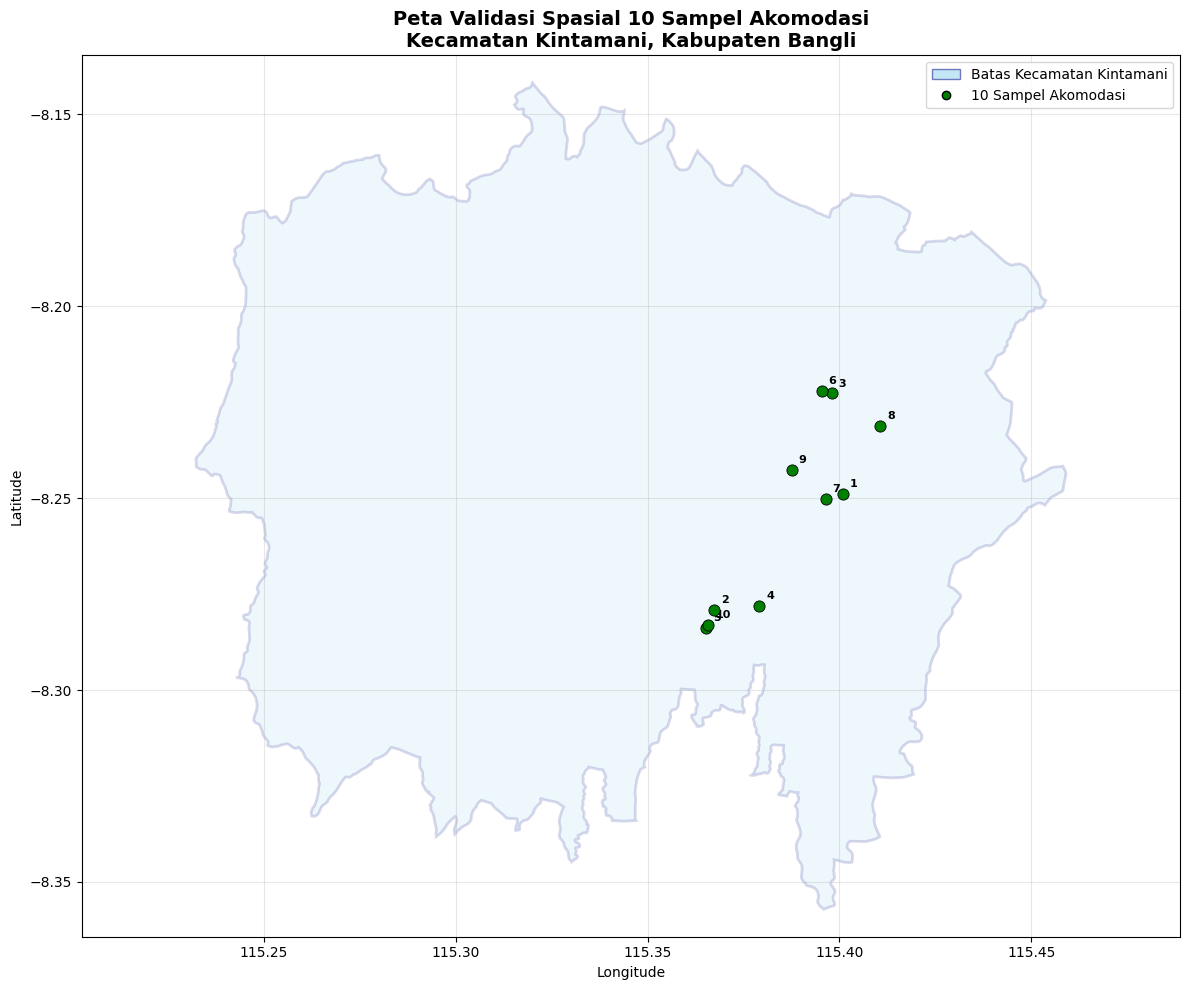

Peta PNG berhasil disimpan!
Lokasi file: /content/drive/MyDrive/akomodasi_kintamani_2501010381/reports/peta_validasi_10_sampel.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from shapely.geometry import shape

# 1. Membaca ulang data validasi dari Google Drive
validasi_path = f"{BASE_DIR}/docs/validasi_10_sampel.csv"
validasi = pd.read_csv(validasi_path)

# 2. Mengambil geometri batas Kintamani
geom = shape(batas_kintamani["features"][0]["geometry"])

# 3. Membuat kanvas peta
fig, ax = plt.subplots(figsize=(12, 10))

# 4. Menggambar batas wilayah Kintamani
geometries = (
    list(geom.geoms)
    if geom.geom_type == "MultiPolygon"
    else [geom]
)

for polygon in geometries:
    x, y = polygon.exterior.xy

    ax.fill(
        x, y,
        alpha=0.15,
        edgecolor="navy",
        facecolor="skyblue",
        linewidth=2
    )

# 5. Menggambar 10 titik sampel akomodasi
ax.scatter(
    validasi["lon"],
    validasi["lat"],
    color="green",
    s=65,
    edgecolors="black",
    linewidths=0.6,
    zorder=5,
    label="Sampel akomodasi"
)

# 6. Memberikan nomor pada setiap titik
for i, row in validasi.reset_index(drop=True).iterrows():
    ax.annotate(
        str(i + 1),
        (row["lon"], row["lat"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
        fontweight="bold"
    )

# 7. Judul dan keterangan peta
ax.set_title(
    "Peta Validasi Spasial 10 Sampel Akomodasi\n"
    "Kecamatan Kintamani, Kabupaten Bangli",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

# 8. Legenda
ax.legend(handles=[
    mpatches.Patch(
        facecolor="skyblue",
        edgecolor="navy",
        alpha=0.5,
        label="Batas Kecamatan Kintamani"
    ),
    plt.Line2D(
        [], [],
        marker="o",
        color="green",
        linestyle="None",
        markeredgecolor="black",
        label="10 Sampel Akomodasi"
    )
])

ax.grid(alpha=0.3)
ax.set_aspect("equal", adjustable="datalim")

plt.tight_layout()

# 9. Menyimpan gambar PNG
output_png = (
    f"{BASE_DIR}/reports/peta_validasi_10_sampel.png"
)

plt.savefig(
    output_png,
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print("Peta PNG berhasil disimpan!")
print("Lokasi file:", output_png)

In [ ]:
import os

output_png = f"{BASE_DIR}/reports/peta_validasi_10_sampel.png"

if os.path.exists(output_png):
    print("PNG BERHASIL DIBUAT!")
    print("Ukuran file:", round(os.path.getsize(output_png) / 1024, 2), "KB")
    print("Lokasi:", output_png)
else:
    print("File PNG belum ditemukan.")

PNG BERHASIL DIBUAT!
Ukuran file: 305.24 KB
Lokasi: /content/drive/MyDrive/akomodasi_kintamani_2501010381/reports/peta_validasi_10_sampel.png


In [ ]:
import os

folder_proyek = BASE_DIR

for root, dirs, files in os.walk(folder_proyek):
    level = root.replace(folder_proyek, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

akomodasi_kintamani_2501010381/
    data/
        raw/
            osm_akomodasi_kintamani_20261109_041952.json
        interim/
            akomodasi_kintamani.csv
    notebooks/
    docs/
        query_overpass.txt
        perbandingan_bps.csv
        provenance.json
        data_dictionary.csv
        data_ethics_checklist.csv
        validasi_10_sampel.csv
    reports/
        peta_akomodasi_kintamani.html
        peta_validasi_10_sampel.html
        peta_validasi_10_sampel.png


In [14]:
!pip install reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 15.5 MB/s  0:00:00


In [15]:

# ============================================================
# LAPORAN FINAL AKUISISI DATA AKOMODASI KECAMATAN KINTAMANI
# Fadhil Firjatullah | 2501010381
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER, TA_LEFT
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle,
    PageBreak, Image, KeepTogether
)
from reportlab.lib.utils import ImageReader

# ------------------------------------------------------------
# 1. PERSIAPAN FILE
# ------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/akomodasi_kintamani_2501010381"

data_path = f"{BASE_DIR}/data/interim/akomodasi_kintamani.csv"
validasi_path = f"{BASE_DIR}/docs/validasi_10_sampel.csv"
peta_path = f"{BASE_DIR}/reports/peta_validasi_10_sampel.png"

output_pdf = f"{BASE_DIR}/reports/laporan_akomodasi_kintamani.pdf"
chart_path = f"{BASE_DIR}/reports/grafik_kategori_akomodasi.png"

for path in [data_path, validasi_path, peta_path]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"File tidak ditemukan: {path}")

df = pd.read_csv(data_path)
validasi = pd.read_csv(validasi_path)

# ------------------------------------------------------------
# 2. RINGKASAN DATA
# ------------------------------------------------------------

jumlah_data = len(df)
kategori = df["jenis"].fillna("Tidak diketahui").value_counts()

# Grafik distribusi kategori
plt.figure(figsize=(8, 4.5))
kategori.plot(kind="bar")
plt.title("Distribusi Kategori Akomodasi Kintamani")
plt.xlabel("Kategori")
plt.ylabel("Jumlah objek")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.close()

# Statistik kualitas data
kolom_penting = [
    col for col in ["nama", "jenis", "lat", "lon",
                    "desa", "bintang", "jumlah_kamar", "website"]
    if col in df.columns
]

missing_data = []
for col in kolom_penting:
    jumlah_kosong = int(df[col].isna().sum())
    persentase = jumlah_kosong / jumlah_data * 100 if jumlah_data else 0
    missing_data.append([
        col, jumlah_kosong, f"{persentase:.2f}%"
    ])

jumlah_validasi = len(validasi)
jumlah_dalam_wilayah = (
    validasi["masuk_kintamani"].astype(str).str.lower().eq("ya").sum()
    if "masuk_kintamani" in validasi.columns else 0
)

# ------------------------------------------------------------
# 3. PENGATURAN DOKUMEN
# ------------------------------------------------------------

doc = SimpleDocTemplate(
    output_pdf,
    pagesize=A4,
    rightMargin=2*cm,
    leftMargin=2*cm,
    topMargin=2*cm,
    bottomMargin=2*cm
)

styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="CoverTitle",
    parent=styles["Title"],
    fontName="Helvetica-Bold",
    fontSize=21,
    leading=29,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#253858"),
    spaceAfter=20
))

styles.add(ParagraphStyle(
    name="SubTitleCustom",
    parent=styles["Normal"],
    fontSize=12,
    leading=18,
    alignment=TA_CENTER,
    spaceAfter=10
))

styles.add(ParagraphStyle(
    name="SectionCustom",
    parent=styles["Heading2"],
    fontSize=13,
    leading=18,
    textColor=colors.HexColor("#253858"),
    spaceBefore=10,
    spaceAfter=7
))

styles.add(ParagraphStyle(
    name="BodyCustom",
    parent=styles["BodyText"],
    fontSize=9,
    leading=14,
    alignment=TA_LEFT,
    spaceAfter=7
))

styles.add(ParagraphStyle(
    name="SmallCustom",
    parent=styles["BodyText"],
    fontSize=8,
    leading=11,
    spaceAfter=4
))

story = []

def P(text, style="BodyCustom"):
    return Paragraph(text, styles[style])

def make_table(data, widths=None):
    table = Table(data, colWidths=widths, repeatRows=1)
    table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#253858")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("FONTNAME", (0, 1), (-1, -1), "Helvetica"),
        ("FONTSIZE", (0, 0), (-1, -1), 8),
        ("GRID", (0, 0), (-1, -1), 0.4, colors.HexColor("#B8C2CC")),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1),
         [colors.white, colors.HexColor("#F1F4F8")]),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("LEFTPADDING", (0, 0), (-1, -1), 6),
        ("RIGHTPADDING", (0, 0), (-1, -1), 6),
        ("TOPPADDING", (0, 0), (-1, -1), 6),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 6),
    ]))
    return table

def fit_image(path, max_width, max_height):
    img = Image(path)
    ratio = min(max_width / img.imageWidth,
                max_height / img.imageHeight)
    img.drawWidth = img.imageWidth * ratio
    img.drawHeight = img.imageHeight * ratio
    return img

def footer(canvas, document):
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(colors.grey)
    canvas.drawString(2*cm, 1.1*cm,
                      "Akuisisi Data & Manajemen Data | INSTIKI")
    canvas.drawRightString(
        A4[0] - 2*cm, 1.1*cm,
        f"Halaman {document.page}"
    )
    canvas.restoreState()

# ------------------------------------------------------------
# 4. HALAMAN SAMPUL
# ------------------------------------------------------------

story.append(Spacer(1, 3*cm))
story.append(P("LAPORAN AKUISISI DATA", "CoverTitle"))
story.append(P(
    "DATA AKOMODASI<br/>KECAMATAN KINTAMANI",
    "CoverTitle"
))
story.append(Spacer(1, 1.2*cm))
story.append(P(
    "Kabupaten Bangli, Provinsi Bali",
    "SubTitleCustom"
))
story.append(Spacer(1, 2*cm))

identitas = [
    ["Nama", "Fadhil Firjatullah"],
    ["NIM", "2501010381"],
    ["Mata Kuliah", "Akuisisi Data & Manajemen Data"],
    ["Kode Mata Kuliah", "BIFP-243"],
    ["Institusi", "INSTIKI"],
    ["Tahun", "2026"]
]

t = Table(identitas, colWidths=[4*cm, 9*cm])
t.setStyle(TableStyle([
    ("FONTNAME", (0, 0), (-1, -1), "Helvetica"),
    ("FONTSIZE", (0, 0), (-1, -1), 10),
    ("GRID", (0, 0), (-1, -1), 0.4, colors.lightgrey),
    ("BACKGROUND", (0, 0), (0, -1), colors.HexColor("#E9EEF5")),
    ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
    ("PADDING", (0, 0), (-1, -1), 9),
]))
story.append(t)
story.append(Spacer(1, 3*cm))
story.append(P(
    "Laporan ini disusun sebagai dokumentasi proses akuisisi, "
    "pengolahan, pemeriksaan, dan validasi data akomodasi "
    "di Kecamatan Kintamani.",
    "SubTitleCustom"
))
story.append(PageBreak())

# ------------------------------------------------------------
# 5. PENDAHULUAN
# ------------------------------------------------------------

story.append(P("1. PENDAHULUAN", "SectionCustom"))

story.append(P(
    "<b>1.1 Latar Belakang</b><br/>"
    "Data akomodasi merupakan salah satu informasi penting dalam "
    "memahami ketersediaan fasilitas penginapan pada suatu wilayah. "
    "Kecamatan Kintamani di Kabupaten Bangli memiliki aktivitas "
    "pariwisata yang berkaitan dengan keberadaan berbagai jenis "
    "akomodasi. Oleh karena itu, diperlukan proses pengumpulan dan "
    "pengolahan data untuk memperoleh gambaran awal mengenai objek "
    "akomodasi yang tercatat secara terbuka."
))

story.append(P(
    "<b>1.2 Tujuan</b><br/>"
    "Kegiatan ini bertujuan untuk memperoleh data akomodasi dari "
    "OpenStreetMap, mengolah data menjadi dataset terstruktur, "
    "memeriksa kualitas atribut dan lokasi, membandingkan informasi "
    "dengan publikasi BPS, serta melakukan validasi spasial terhadap "
    "sampel objek."
))

story.append(P("2. SUMBER DATA DAN METODOLOGI", "SectionCustom"))

story.append(P(
    "<b>2.1 Sumber Data</b><br/>"
    "1. OpenStreetMap (OSM): sumber data objek akomodasi dan atribut "
    "yang tersedia pada peta terbuka.<br/>"
    "2. BIG Satu Peta: sumber batas administrasi Kecamatan Kintamani "
    "melalui layanan Peta Wilayah Administrasi Kecamatan.<br/>"
    "3. Badan Pusat Statistik Kabupaten Bangli: publikasi "
    "<i>Kecamatan Kintamani Dalam Angka 2025</i>, khususnya tabel "
    "6.1.1 dengan referensi tahun 2024."
))

story.append(P(
    "<b>2.2 Metode Akuisisi</b><br/>"
    "Data objek diperoleh melalui query Overpass API berdasarkan "
    "tag objek akomodasi di OpenStreetMap. Hasil respons disimpan "
    "sebagai data mentah JSON, kemudian diolah menjadi CSV. "
    "Batas administrasi diperoleh dari layanan BIG dan digunakan "
    "sebagai acuan pemeriksaan lokasi."
))

story.append(P(
    "<b>2.3 Alur Pengolahan</b><br/>"
    "Akuisisi data → penyimpanan data mentah → ekstraksi atribut → "
    "pembersihan dan pemeriksaan data → perbandingan BPS → "
    "pemilihan sampel → validasi atribut dan spasial → visualisasi "
    "dan pelaporan."
))

story.append(PageBreak())

# ------------------------------------------------------------
# 6. HASIL AKUISISI DAN KUALITAS DATA
# ------------------------------------------------------------

story.append(P("3. HASIL AKUISISI DATA", "SectionCustom"))

story.append(P(
    f"Berdasarkan hasil akuisisi OpenStreetMap, diperoleh "
    f"<b>{jumlah_data} objek</b> yang tercatat sebagai objek "
    "akomodasi pada wilayah kajian. Data disimpan dalam format "
    "JSON sebagai data mentah dan CSV sebagai dataset hasil "
    "pengolahan."
))

category_table = [["Kategori", "Jumlah"]]
for name, count in kategori.items():
    category_table.append([str(name), str(int(count))])

category_table.append(["TOTAL", str(jumlah_data)])
story.append(make_table(category_table, [9*cm, 4*cm]))
story.append(Spacer(1, 12))

story.append(P(
    "<b>Grafik Distribusi Kategori Akomodasi</b>",
    "BodyCustom"
))
story.append(fit_image(chart_path, 15*cm, 8*cm))
story.append(Spacer(1, 8))

story.append(P("4. PEMERIKSAAN KUALITAS DATA", "SectionCustom"))

story.append(P(
    "Pemeriksaan kualitas dilakukan dengan memperhatikan "
    "kelengkapan atribut, koordinat, dan kemungkinan data ganda. "
    "Ringkasan nilai kosong pada atribut penting ditampilkan "
    "berikut ini."
))

missing_table = [["Atribut", "Jumlah Kosong", "Persentase"]]
missing_table.extend(missing_data)
story.append(make_table(missing_table, [6*cm, 4*cm, 4*cm]))
story.append(Spacer(1, 8))

story.append(P(
    "Hasil pemeriksaan sebelumnya menunjukkan tidak ditemukan "
    "duplikasi dan tidak terdapat koordinat kosong pada 32 objek. "
    "Terdapat atribut yang belum lengkap, antara lain desa, "
    "bintang, jumlah kamar, dan website. Kekosongan atribut "
    "tidak selalu berarti objek tidak memiliki informasi tersebut "
    "di dunia nyata, melainkan informasi tersebut belum tercatat "
    "pada data OSM yang diperoleh."
))

story.append(PageBreak())

# ------------------------------------------------------------
# 7. PERBANDINGAN BPS DAN VALIDASI
# ------------------------------------------------------------

story.append(P("5. PERBANDINGAN DENGAN DATA BPS", "SectionCustom"))

story.append(P(
    "Publikasi Kecamatan Kintamani Dalam Angka 2025 dari BPS "
    "Kabupaten Bangli memuat informasi pada tabel 6.1.1 dengan "
    "referensi tahun 2024. Tabel tersebut mencatat jumlah "
    "desa/kelurahan yang memiliki fasilitas hotel dan penginapan."
))

bps_table = [
    ["Kategori BPS", "Jumlah Desa/Kelurahan"],
    ["Hotel", "4"],
    ["Penginapan", "10"]
]
story.append(make_table(bps_table, [8*cm, 6*cm]))
story.append(Spacer(1, 8))

story.append(P(
    "<b>Catatan perbandingan:</b> Angka BPS tersebut merupakan "
    "jumlah desa/kelurahan yang memiliki fasilitas, sedangkan "
    "dataset OSM berisi jumlah objek akomodasi individual. "
    "Keduanya memiliki satuan pengukuran berbeda sehingga tidak "
    "dapat digunakan untuk menghitung persentase kelengkapan "
    "data OSM secara langsung."
))

story.append(P("6. VALIDASI 10 SAMPEL", "SectionCustom"))

story.append(P(
    f"Sebanyak {jumlah_validasi} sampel dipilih untuk pemeriksaan "
    "atribut dan lokasi. Pemeriksaan nama, jenis, dan koordinat "
    "dilakukan dengan merujuk pada detail objek OpenStreetMap. "
    "Pemeriksaan spasial dilakukan dengan membandingkan titik "
    "koordinat terhadap poligon batas administrasi Kecamatan "
    "Kintamani."
))

story.append(P(
    f"Hasil pemeriksaan spasial menunjukkan "
    f"<b>{jumlah_dalam_wilayah} dari {jumlah_validasi} sampel</b> "
    "berada di dalam poligon Kecamatan Kintamani berdasarkan "
    "pengujian titik terhadap geometri wilayah."
))

story.append(P(
    "<b>Peta Validasi Spasial 10 Sampel</b>",
    "BodyCustom"
))
story.append(fit_image(peta_path, 15*cm, 13*cm))
story.append(Spacer(1, 5))

story.append(P(
    "Validasi ini menunjukkan konsistensi data terhadap informasi "
    "OSM dan batas administrasi yang digunakan. Validasi tersebut "
    "tidak secara otomatis membuktikan bahwa seluruh objek masih "
    "beroperasi atau seluruh kategorinya telah terverifikasi "
    "secara independen di lapangan."
))

story.append(PageBreak())

# ------------------------------------------------------------
# 8. ETIKA, KETERBATASAN, KESIMPULAN, REFERENSI
# ------------------------------------------------------------

story.append(P("7. ETIKA DAN KETERBATASAN DATA", "SectionCustom"))

story.append(P(
    "Data OpenStreetMap merupakan data terbuka yang disediakan "
    "oleh kontributor. Penggunaan data perlu mencantumkan atribusi "
    "OpenStreetMap dan memperhatikan ketentuan lisensi Open "
    "Database License (ODbL). Data batas administrasi diperoleh "
    "dari layanan BIG Satu Peta dan sumbernya dicantumkan dalam "
    "dokumentasi proyek."
))

story.append(P(
    "Keterbatasan kegiatan ini meliputi kemungkinan data OSM belum "
    "mencakup seluruh objek akomodasi, adanya atribut yang kosong, "
    "perbedaan satuan antara data OSM dan BPS, serta belum "
    "dilakukannya verifikasi lapangan terhadap seluruh objek. "
    "Kategori yang tercatat pada OSM merupakan hasil klasifikasi "
    "berdasarkan tag yang tersedia dan bukan jaminan status "
    "operasional terkini."
))

story.append(P("8. KESIMPULAN", "SectionCustom"))

story.append(P(
    f"Proses akuisisi berhasil menghasilkan dataset sebanyak "
    f"{jumlah_data} objek akomodasi dari OpenStreetMap di wilayah "
    "kajian Kecamatan Kintamani. Dataset telah disimpan dalam "
    "format terstruktur dan diperiksa dari sisi kelengkapan "
    "atribut serta koordinat. Perbandingan dengan publikasi BPS "
    "memberikan konteks statistik wilayah, dengan memperhatikan "
    "perbedaan satuan data. Pemeriksaan terhadap 10 sampel "
    "menunjukkan seluruh titik sampel yang diperiksa berada "
    "di dalam batas administrasi Kintamani. Hasil ini dapat "
    "digunakan sebagai gambaran awal dan masih dapat ditingkatkan "
    "melalui verifikasi lapangan serta pembaruan data berkala."
))

story.append(P("9. REFERENSI DAN DOKUMENTASI", "SectionCustom"))

story.append(P(
    "1. OpenStreetMap Contributors. OpenStreetMap. "
    "https://www.openstreetmap.org/<br/>"
    "2. Overpass API. Layanan query data OpenStreetMap. "
    "https://overpass-api.de/<br/>"
    "3. Badan Pusat Statistik Kabupaten Bangli. (2025). "
    "<i>Kecamatan Kintamani Dalam Angka 2025</i>. "
    "https://banglikab.bps.go.id/id/publication/2025/09/26/"
    "8bd335021722e75f43dae2ad/kecamatan-kintamani-dalam-angka-2025.html<br/>"
    "4. Badan Informasi Geospasial. BIG Satu Peta, "
    "Peta Wilayah Administrasi Kecamatan. "
    "https://kspservices.big.go.id/satupeta/rest/services/"
    "PUBLIK/BATAS_WILAYAH/MapServer/3"
))

story.append(Spacer(1, 10))
story.append(P(
    "<b>Dokumentasi pendukung:</b> File JSON, CSV, query Overpass, "
    "provenance, data dictionary, checklist etika, data validasi, "
    "serta peta interaktif HTML disimpan pada folder proyek "
    "Google Drive."
))

# ------------------------------------------------------------
# 9. MEMBANGUN PDF
# ------------------------------------------------------------

doc.build(
    story,
    onFirstPage=footer,
    onLaterPages=footer
)

print("============================================")
print("LAPORAN PDF BERHASIL DIBUAT!")
print("============================================")
print("Nama file:", os.path.basename(output_pdf))
print("Lokasi:", output_pdf)
print("Ukuran:", round(os.path.getsize(output_pdf) / 1024, 2), "KB")


LAPORAN PDF BERHASIL DIBUAT!
Nama file: laporan_akomodasi_kintamani.pdf
Lokasi: /content/drive/MyDrive/akomodasi_kintamani_2501010381/reports/laporan_akomodasi_kintamani.pdf
Ukuran: 423.8 KB
